# Does brand last? Lifts that fade, and going dark

**Audience:** analysts who have read the practitioner guide (01) and want to know how far to trust a long-term return.

**The question.** A quarter of brand spend lifts awareness. Does the lift stay, or does it drain away once the spend stops? The answer sets almost all of a channel's 5-year return, and it decides what happens to sales if you go dark.

Until `fading=` the package, like Cain (2022), assumed every lift lasts: spend enters the weekly growth of the brand metrics, so a lift stays unless the long-run ties pull it back. This guide shows what that assumption costs when it is wrong, and what `fading=` can and cannot tell you.

**Learning objectives.** By the end you will be able to:

- **§1** Tell the two stories apart: a lift that lasts and a lift that fades.
- **§2** Fit the model with and without `fading=` on data where lifts fade, and read the fade share and half-life.
- **§3** See how far the lasting-only model overstates the 5-year return.
- **§4** See what going dark for a quarter does to sales under each model.
- **§5** Read the results across many simulated data sets, including whether a dark spell in the data settles the question.

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_vecm import BayesianVECM, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
LASTS_COLOUR, FADES_COLOUR, TRUTH_COLOUR = "#eb6834", "#2a78d6", "black"
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES = "organic_sales"
CHANNELS = ["brand_spend", "pr_reach", "sponsorship_reach"]
HORIZON = 260
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())


def truth_sales(truth, driver, u):
    """Log sales gap when ``driver`` moves by ``u`` (one value per week), through the truth."""
    pi = truth.alpha @ truth.beta.T
    b = truth.b[:, driver]
    delta = truth.fade_decay[driver]
    share = truth.fade_share if np.isfinite(truth.fade_half_life[driver]) else 0.0
    y, dy, stock, out = np.zeros(3), np.zeros(3), 0.0, []
    for t in range(len(u)):
        if t > 0:
            stock = delta * stock + u[t - 1]
        dy = pi @ y + truth.gamma @ dy + b * u[t] - share * (1 - delta) * b * stock
        y = y + dy
        out.append(y[0])
    return np.array(out)


def interval(x, fmt="{:.2f}"):
    lo, hi = np.percentile(x, TAILS)
    return f"{fmt.format(np.median(x))} ({fmt.format(lo)} to {fmt.format(hi)})"

## §1 Two stories

**Plain English:** in the first story a campaign lifts awareness and the lift stays: awareness stops rising when the campaign ends but does not fall back. Sales follow awareness up to a new level and stay there. In the second story part of the lift drains away over the following months, and sales slide back with it.

`simulate_brand_data(exog_fade=..., exog_fade_share=...)` simulates the second story. The share `exog_fade_share` of each lift drains away with half-life `exog_fade` weeks; the rest stays. The chart shows the sales path after one week of brand spend, through the true parameters, for three versions of the same brand.

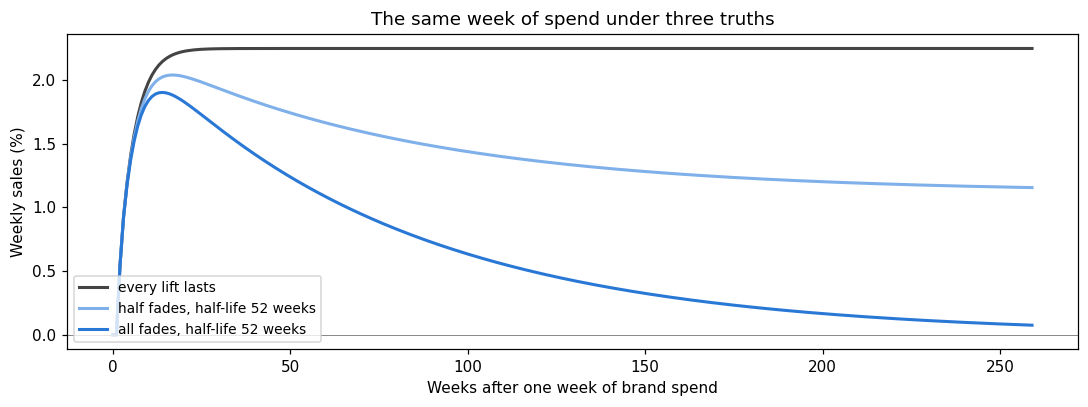

In [3]:
u = np.zeros(HORIZON)
u[0] = 1.0
stories = {
    "every lift lasts": simulate_brand_data(),
    "half fades, half-life 52 weeks": simulate_brand_data(
        exog_fade=dict.fromkeys(CHANNELS, 52.0), exog_fade_share=0.5
    ),
    "all fades, half-life 52 weeks": simulate_brand_data(exog_fade=dict.fromkeys(CHANNELS, 52.0)),
}
fig, ax = plt.subplots(figsize=(10, 3.8))
for (label, sim), colour in zip(stories.items(), ["#444444", "#7fb0ea", FADES_COLOUR], strict=True):
    path = 100 * np.expm1(truth_sales(sim.truth, 0, u))
    ax.plot(np.arange(HORIZON), path, color=colour, lw=2, label=label)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Weeks after one week of brand spend")
ax.set_ylabel("Weekly sales (%)")
ax.set_title("The same week of spend under three truths")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The first weeks look almost the same in all three: that is the part a media mix model sees. The stories part company after a few months, which is exactly where five years of weekly data has the least to say.

## §2 Fit both models where lifts fade

The data below is the default simulated brand with **all of every lift fading, half-life 52 weeks**, so the lasting-only model is wrong by construction. Two fits:

- **Lasting only:** the default model. Every lift lasts.
- **With `fading=`:** each channel gets `fade_share` (the share of a lift that drains away, prior flat on 0 to 1) and `fade_half_life` (weeks, prior centred on a year).

In [4]:
data = simulate_brand_data(exog_fade=dict.fromkeys(CHANNELS, 52.0))
endog, exog, truth = data.endog, data.exog, data.truth
j = list(exog.columns).index("brand_spend")

fits = {}
for label, extra in {"lasting only": {}, "with fading": {"fading": CHANNELS}}.items():
    fits[label] = BayesianVECM(**SPEC, **extra).fit(
        endog,
        exog=exog,
        draws=DRAWS,
        tune=TUNE,
        chains=CHAINS,
        target_accept=0.95,
        random_seed=3,
        progressbar=False,
    )
    divergences = int(fits[label].idata_.sample_stats["diverging"].sum())
    print(f"{label}: {divergences} divergences")

post = fits["with fading"].idata_.posterior
rows = []
for k, ch in enumerate(CHANNELS):
    rows.append(
        {
            "channel": ch,
            "lasting share": interval(1 - post["fade_share"].values[..., k].ravel()),
            "fade half-life (weeks)": interval(
                post["fade_half_life"].values[..., k].ravel(), "{:.0f}"
            ),
        }
    )
print("Truth: lasting share 0, half-life 52 weeks")
pd.DataFrame(rows).set_index("channel")

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B]


lasting only: 0 divergences


NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, B, fade_share, fade_half_life]


with fading: 0 divergences
Truth: lasting share 0, half-life 52 weeks


,lasting share,fade half-life (weeks)
channel,,
brand_spend,0.59 (0.07 to 0.97),60 (19 to 190)
pr_reach,0.29 (0.02 to 0.86),30 (11 to 118)
sponsorship_reach,0.47 (0.04 to 0.95),47 (12 to 163)


**Reading the table.** The truth is a lasting share of 0: every lift drains away. The fit leans that way only weakly. For brand spend the lasting share comes out at 0.59 with an interval from 0.07 to 0.97, and the half-life brackets the true 52 weeks loosely. That is the honest answer from five years of data: the model cannot tell how much of a lift stays. This data set is on the unlucky side; §5 shows the same fit across many.

## §3 What it does to the long-term return

The return from one more unit of brand spend for one week, as the extra sales summed over 1 and 5 years in weeks of sales. `exog_irf()` includes the fade, so it settles at the lasting share of the impact path.

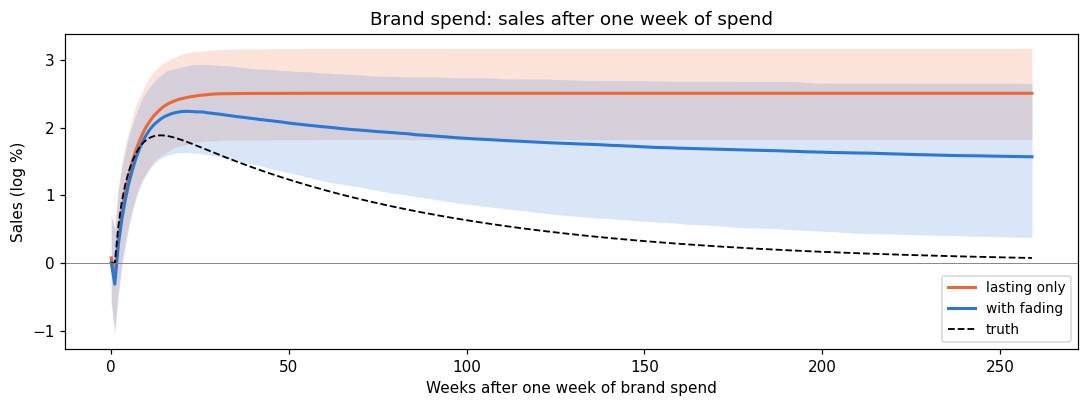

,truth,lasting only,with fading
window,,,
1 year,0.78,1.14 (0.80 to 1.47),1.01 (0.69 to 1.34)
5 years,1.63,6.42 (4.65 to 8.17),4.62 (2.25 to 6.97)


In [5]:
pulses = {}
for label, model in fits.items():
    path = model.exog_irf(steps=HORIZON - 1).sel(
        response_variable=SALES, exog_variable="brand_spend"
    )
    pulses[label] = path.stack(s=("chain", "draw")).transpose("s", "horizon").values
true_path = truth_sales(truth, j, u)

fig, ax = plt.subplots(figsize=(10, 3.8))
weeks = np.arange(HORIZON)
for (label, path), colour in zip(pulses.items(), [LASTS_COLOUR, FADES_COLOUR], strict=True):
    lo, hi = np.percentile(100 * path, TAILS, axis=0)
    ax.fill_between(weeks, lo, hi, color=colour, alpha=0.18, lw=0)
    ax.plot(weeks, np.median(100 * path, axis=0), color=colour, lw=2, label=label)
ax.plot(weeks, 100 * true_path, color=TRUTH_COLOUR, ls="--", lw=1.2, label="truth")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Weeks after one week of brand spend")
ax.set_ylabel("Sales (log %)")
ax.set_title("Brand spend: sales after one week of spend")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

rows = []
for label, w in (("1 year", 52), ("5 years", HORIZON)):
    row = {"window": label, "truth": f"{np.expm1(true_path[:w]).sum():.2f}"}
    for fit_label, path in pulses.items():
        row[fit_label] = interval(np.expm1(path[:, :w]).sum(axis=1))
    rows.append(row)
pd.DataFrame(rows).set_index("window")

**Reading the chart and table.** Both fits follow the truth for the first months, and both get the 1-year return about right. After that the lasting-only fit holds sales up for good, so its 5-year return is about four times the truth, with an interval nowhere near it. The fading fit bends down part of the way: about three times the truth here, with a much wider interval whose lower end (2.25) still sits above the truth (1.63). Across many data sets (§5) the fading fit does better than on this one.

## §4 Going dark for a quarter

Brand spend is switched off for 13 weeks and then returns to average. Every other driver stays at its average. The line is weekly sales against carrying on, through each fit's forecast and through the truth.

- **Lasting only:** the growth lost while spend was off never comes back, so sales settle below the old path for good.
- **Fading:** the fading part of past lifts drains while spend is off, so sales fall further at first; when spend returns that part rebuilds and sales come back.

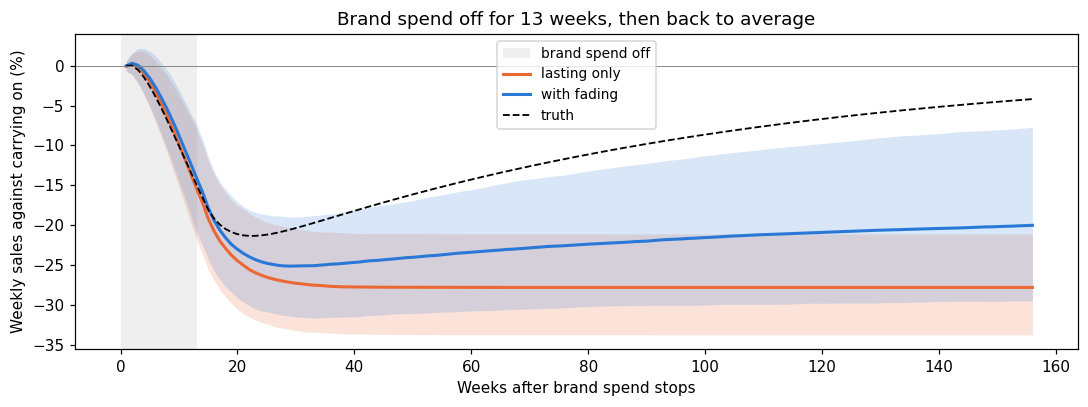

,truth,lasting only,with fading
week,,,
when it restarts,-14.9%,-15.4% (-21.8% to -7.9%),-14.1% (-20.9% to -7.3%)
1 year on,-15.7%,-27.8% (-33.7% to -21.1%),-23.9% (-31.0% to -16.6%)
3 years on,-4.2%,-27.8% (-33.7% to -21.1%),-20.0% (-29.5% to -7.7%)


In [6]:
DARK_WEEKS, FOLLOW = 13, 156
base = np.zeros((FOLLOW, exog.shape[1]))
plan = base.copy()
plan[:DARK_WEEKS, j] = -1.0  # a linear channel here averages one unit: -1 is off
dark = {}
for label, model in fits.items():
    paths = []
    for x in (base, plan):
        fc = model.sample_posterior_predictive(FOLLOW, exog_future=x, random_seed=0)
        paths.append(fc.posterior_predictive["y"].sel(variable=SALES).values.reshape(-1, FOLLOW))
    dark[label] = 100 * np.expm1(paths[1] - paths[0])
off = np.zeros(FOLLOW)
off[:DARK_WEEKS] = -1.0
true_dark = 100 * np.expm1(truth_sales(truth, j, off))

fig, ax = plt.subplots(figsize=(10, 3.8))
weeks = np.arange(1, FOLLOW + 1)
ax.axvspan(0, DARK_WEEKS, color="grey", alpha=0.12, lw=0, label="brand spend off")
for (label, gap), colour in zip(dark.items(), [LASTS_COLOUR, FADES_COLOUR], strict=True):
    lo, hi = np.percentile(gap, TAILS, axis=0)
    ax.fill_between(weeks, lo, hi, color=colour, alpha=0.18, lw=0)
    ax.plot(weeks, np.median(gap, axis=0), color=colour, lw=2, label=label)
ax.plot(weeks, true_dark, color=TRUTH_COLOUR, ls="--", lw=1.2, label="truth")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Weeks after brand spend stops")
ax.set_ylabel("Weekly sales against carrying on (%)")
ax.set_title(f"Brand spend off for {DARK_WEEKS} weeks, then back to average")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

rows = []
for label, w in (("when it restarts", DARK_WEEKS), ("1 year on", 52), ("3 years on", FOLLOW)):
    row = {"week": label, "truth": f"{true_dark[w - 1]:.1f}%"}
    for fit_label, gap in dark.items():
        row[fit_label] = interval(gap[:, w - 1], "{:.1f}%")
    rows.append(row)
pd.DataFrame(rows).set_index("week")

**Reading the chart and table.** Both fits and the truth agree on the dip while spend is off. After spend returns the stories split. The lasting-only fit says a quarter off costs a fixed 28% of sales for ever. In the truth most of it comes back: 4% down after three years. The fading fit recovers part of the way (20% down, interval 8% to 30%). For a budget meeting the difference matters: under the first story a cut is a permanent loss, under the second it is a dip that mostly comes back.

## §5 Across many data sets

One data set can be lucky or unlucky. `tools/fade_check.py` fitted five seeds of four truths (every lift lasts, or all of it fades with half-life 26, 52 or 104 weeks) with both models. The table gives the 5-year return from one week of brand spend: the median across seeds of each fit's median, its ratio to the truth, and how often the 90% interval held the truth.

In [7]:
fade_runs = pd.read_csv(ROOT / "tools" / "fade_check_results.csv")
fade_runs["covered"] = (fade_runs.lo90 <= fade_runs.truth) & (fade_runs.truth <= fade_runs.hi90)
five = fade_runs[fade_runs.quantity == "pulse sales, 5 years"]
table = five.groupby(["setting", "fit"], sort=False).agg(
    truth=("truth", "median"), model=("median", "median"), held=("covered", "mean")
)
table["model / truth"] = (table.model / table.truth).map("{:.1f}x".format)
table["interval held the truth"] = table.held.map("{:.0%}".format)
table[["truth", "model", "model / truth", "interval held the truth"]].round(2).unstack("fit")

truth                        model                model / truth               \
fit       permanent model fading model permanent model fading model permanent model fading model   
setting                                                                                            
permanent            5.72         5.72            5.73         4.15            1.0x         0.7x   
fade 26              0.85         0.85            5.07         2.62            6.0x         3.1x   
fade 52              1.63         1.63            5.35         3.31            3.3x         2.0x   
fade 104             2.75         2.75            5.55         3.63            2.0x         1.3x   

          interval held the truth               
fit               permanent model fading model  
setting                                         
permanent                    100%          80%  
fade 26                        0%          40%  
fade 52                        0%         100%  
fade 104                       0%         100%

- **When lifts fade, the lasting-only model is confidently wrong.** It overstates the 5-year return two to six times and its interval misses the truth in every data set.
- **The fading model is honest but loose.** Its interval holds the truth in most data sets, but it is wide, and when lifts truly last it comes out about a quarter low: with weak evidence it leans towards the middle.

**Does a dark spell help?** `tools/dark_period_check.py` repeats the test on data where brand spend was switched off for 26 or 52 weeks in the middle of the sample, with the fading model only. If a dark spell carries the information, the fade share's interval should narrow.

In [8]:
dark_runs = pd.read_csv(ROOT / "tools" / "dark_period_check_results.csv")
dark_runs["covered"] = (dark_runs.lo90 <= dark_runs.true) & (dark_runs.true <= dark_runs.hi90)
dark_runs["width"] = dark_runs.hi90 - dark_runs.lo90
order = ["never off", "off 26 weeks", "off 52 weeks"]
share = dark_runs[dark_runs.quantity == "fade_share"]
five = dark_runs[dark_runs.quantity == "pulse sales, 5 years"]
summary = pd.concat(
    {
        "fade share: median": share.groupby(["truth", "dark"])["median"].median(),
        "fade share: interval width": share.groupby(["truth", "dark"])["width"].median(),
        "5-year return / truth": (five["median"] / five["true"])
        .groupby([five.truth, five.dark])
        .median(),
        "5-year interval held the truth": five.groupby(["truth", "dark"])["covered"].mean(),
    },
    axis=1,
)
summary.reindex(order, level="dark").round(2)

fade share: median  fade share: interval width  5-year return / truth  \
truth dark                                                                                  
fades never off                   0.59                        0.88                   2.03   
      off 26 weeks                0.73                        0.69                   1.49   
      off 52 weeks                0.83                        0.44                   1.34   
lasts never off                   0.46                        0.89                   0.71   
      off 26 weeks                0.29                        0.85                   0.76   
      off 52 weeks                0.33                        0.75                   0.84   

                    5-year interval held the truth  
truth dark                                          
fades never off                                1.0  
      off 26 weeks                             0.8  
      off 52 weeks                             0.8  
lasts never off                                0.8  
      off 26 weeks                             0.6  
      off 52 weeks                             0.6

**Reading the table.** A dark spell helps, and a longer one helps more, but it does not settle the question on its own.

- **When lifts fade**, the fade share moves towards the truth of 1 and its interval narrows: from a width of about 0.9 with spend never off to about 0.4 with a year off. The 5-year return comes down from about twice the truth to about a third above it.
- **When lifts last**, the fade share moves towards 0 and the 5-year return closer to the truth, but less clearly, and the intervals hold the truth less often.
- **The 1-year return is right in every setting.** The question is only about the years after.

So a period when a channel was off is the most useful thing your data can hold for this question. Without one, report the 5-year return as a range that depends on how much of a lift lasts.

## What this means

- **Whether brand lasts is an assumption until the data say otherwise.** The lasting-only model builds it in. If it is wrong, every 5-year figure is inflated and its interval will not warn you.
- **Use `fading=` for brand channels by default** (guide 08 does). It costs a wider interval and a longer fit, and it keeps the 5-year return honest about what the data cannot settle.
- **Report three numbers:** the 1-year return (robust), the 5-year return with `fading=`, and the going-dark scenario. Say plainly that the lasting share is uncertain.
- **The best evidence is a period when a channel was off.** If your brand has ever gone dark, keep those weeks in the data and note them.

**How it was checked.** `tools/fade_check.py` (four truths, five seeds, two fits each) and `tools/dark_period_check.py` (two truths, three dark settings, five seeds). Results are in the matching `_results.csv` files.

**Method.** Cain (2022) ties brand metrics to base sales by cointegration and treats a lasting effect as one that enters the trending metrics. `fading=` adds a decaying part on top, so the data can say how much of a lift lasts. Cain (2025) explains why a long adstock cannot stand in for brand building; this guide asks the next question, of how much of the brand lift itself lasts.